#  Notebook 2 — monitoring_device_operations.csv
**Projet Data Mining — Investigation sur plusieurs datasets**





## Cellule 1 — Imports et chargement


In [ ]:
import os, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.pairwise import haversine_distances
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
import networkx as nx

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 120)
sns.set_theme(style="whitegrid")

FILES = ["monitoring_device_operations.csv", "monitoring_sites.csv"]
try:
    from google.colab import files
    if not all(os.path.exists(f) for f in FILES):
        print("Téléverse les deux fichiers :", FILES)
        files.upload()
except ImportError:
    pass

def find(name):
    for p in [name, "/mnt/user-data/uploads/" + name]:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"{name} introuvable : téléverse-le")

raw = pd.read_csv(find(FILES[0]))
sites = pd.read_csv(find(FILES[1]))
sites["site_category"] = sites.site_category.str.strip().str.lower()   # même correction qu'au notebook 1
print("device_operations :", raw.shape, "| sites :", sites.shape)
raw.head()

device_operations : (4994, 11) | sites : (64, 14)


,device_operation_id,site_code,device_reference,operation_start,operation_end,uptime_pct,acoustic_quality,maintenance_type,fault_code,maintenance_provider,record_status
0,DOP-0000001,KNT-KES,DEV-KNTKES-2,2019-01-01T00:00:00,2019-01-31T23:59:59,92.3,85.9,routine inspection,NaN,ECO-SERVICE-2,closed
1,DOP-0000002,KNT-KES,DEV-KNTKES-2,2019-02-01T00:00:00,2019-02-28T23:59:59,80.6,79.6,routine inspection,NaN,ECO-SERVICE-2,closed
2,DOP-0000003,KNT-KES,DEV-KNTKES-2,2019-03-01T00:00:00,2019-03-31T23:59:59,94.9,82.5,routine inspection,NaN,ECO-SERVICE-2,closed
3,DOP-0000004,KNT-KES,DEV-KNTKES-2,2019-04-01T00:00:00,2019-04-30T23:59:59,94.8,84.8,routine inspection,NaN,ECO-SERVICE-2,closed
4,DOP-0000005,KNT-KES,DEV-KNTKES-2,2019-05-01T00:00:00,2019-05-31T23:59:59,87.7,69.2,routine inspection,NaN,ECO-SERVICE-2,closed


## Cellule 2 — Structure et défauts de qualité


In [ ]:
print("Dimensions :", raw.shape)
print(raw.dtypes)

na = raw.isna().sum(); print("\nValeurs manquantes :"); print(na[na > 0])
print("\nDoublons (lignes entières) :", raw.duplicated().sum())
print("Doublons sur l'identifiant d'opération :", raw.device_operation_id.duplicated().sum())

print("\nValeurs distinctes par colonne catégorielle :")
for c in ["maintenance_type", "fault_code", "maintenance_provider", "record_status"]:
    print(f"\n{c} :"); print(raw[c].value_counts(dropna=False))

def pattern(x):
    import re
    return re.sub(r"[A-Za-z]", "a", re.sub(r"\d", "9", str(x)))
print("\nFormats de operation_start :"); print(raw.operation_start.map(pattern).value_counts())
print("\nFormats de operation_end :");   print(raw.operation_end.map(pattern).value_counts())
print("\nuptime_pct non convertible directement en nombre :",
      pd.to_numeric(raw.uptime_pct, errors="coerce").isna().sum(), "lignes")

Dimensions : (4994, 11)
device_operation_id      object
site_code                object
device_reference         object
operation_start          object
operation_end            object
uptime_pct               object
acoustic_quality        float64
maintenance_type         object
fault_code               object
maintenance_provider     object
record_status            object
dtype: object

Valeurs manquantes :
fault_code              4805
maintenance_provider      30
dtype: int64

Doublons (lignes entières) : 2
Doublons sur l'identifiant d'opération : 2

Valeurs distinctes par colonne catégorielle :

maintenance_type :
maintenance_type
routine inspection        4785
corrective maintenance     137
sensor replacement          52
ROUTINE INSPECTION          12
Routine Inspection           8
Name: count, dtype: int64

fault_code :
fault_code
NaN                   4805
MICROPHONE_DRIFT        97
STORAGE_LIMIT           56
POWER_INTERRUPTION      36
Name: count, dtype: int64

maintenance_provi

### Interprétation (cellule 2)

- 2 doublons exacts (même identifiant d'opération répété)
- maintenance_type : routine inspection est écrit de 3 façons (ROUTINE INSPECTION : 12 lignes, Routine Inspection : 8). record_status a aussi 3 casses (closed, CLOSED, Closed) et ne contient qu'une seule valeur réelle : colonne sans information.
- operation_end a 4 formats de date : ISO (4 974 lignes), jj/mm/aaaa (8), jj-Mon-aaaa (7) et aaaa/mm/jj (5). operation_start est propre.
- uptime_pct est du texte : 50 valeurs utilisent la virgule décimale ("100,0").
- 30 fournisseurs manquants ; fault_code vide pour 4 805 lignes

## Cellule 3 — Nettoyage



In [ ]:
dev = raw.drop_duplicates().copy()                       # 1) doublons exacts
print("Lignes après suppression des doublons :", len(dev))

# 2) uptime : virgule décimale -> point
dev["uptime"] = pd.to_numeric(dev.uptime_pct.astype(str).str.replace(",", ".", regex=False), errors="coerce")
print("uptime non converti :", dev.uptime.isna().sum())

# 3) casse
dev["maintenance_type"] = dev.maintenance_type.str.strip().str.lower()
dev["record_status"] = dev.record_status.str.strip().str.lower()

# 4) dates : formats mélangés dans operation_end -> format="mixed"
dev["start"] = pd.to_datetime(dev.operation_start)
dev["end"] = pd.to_datetime(dev.operation_end, format="mixed")
dev["ym"] = dev.start.dt.to_period("M")
dev["year"] = dev.start.dt.year
dev["month"] = dev.start.dt.month

# 5) fault_code vide = pas de panne (pas une donnée manquante) ; on le vérifie
dev["fault"] = dev.fault_code.fillna("none")
print("\nmaintenance_type x fault :"); print(pd.crosstab(dev.maintenance_type, dev.fault))

# 6) fournisseur manquant : chaque site n'a qu'UN fournisseur -> on le déduit
prov_by_site = dev.groupby("site_code").maintenance_provider.agg(lambda x: x.dropna().unique().tolist())
print("\nNombre de fournisseurs distincts par site :", prov_by_site.map(len).value_counts().to_dict())
dev["provider_imputed"] = dev.maintenance_provider.isna()
dev["provider"] = dev.maintenance_provider.fillna(dev.site_code.map(prov_by_site.map(lambda l: l[0])))
print("Fournisseurs imputés :", dev.provider_imputed.sum(), "| restant manquants :", dev.provider.isna().sum())

# 7) modèle d'appareil (suffixe du device_reference) et indicateurs de saturation
dev["device_model"] = dev.device_reference.str.extract(r"-(\d+)$")[0]
dev["clip_uptime_100"] = dev.uptime == 100
dev["clip_quality_100"] = dev.acoustic_quality == 100

# 8) jointure avec les sites
dev = dev.merge(sites[["site_code", "site_category", "region", "habitat_category", "elevation_m", "latitude", "longitude"]],
                on="site_code", how="left")
print("\nSites non appariés :", dev.site_category.isna().sum())
print(dev[["device_operation_id", "site_code", "ym", "uptime", "acoustic_quality", "maintenance_type", "fault", "provider", "device_model"]].head())

Lignes après suppression des doublons : 4992
uptime non converti : 0

maintenance_type x fault :
fault                   MICROPHONE_DRIFT  POWER_INTERRUPTION  STORAGE_LIMIT  none
maintenance_type                                                                 
corrective maintenance                45                  36             56     0
routine inspection                     0                   0              0  4803
sensor replacement                    52                   0              0     0

Nombre de fournisseurs distincts par site : {1: 64}
Fournisseurs imputés : 30 | restant manquants : 0

Sites non appariés : 0
  device_operation_id site_code       ym  uptime  acoustic_quality    maintenance_type fault       provider device_model
0         DOP-0000001   KNT-KES  2019-01    92.3              85.9  routine inspection  none  ECO-SERVICE-2            2
1         DOP-0000002   KNT-KES  2019-02    80.6              79.6  routine inspection  none  ECO-SERVICE-2            2
2  

### Interprétation (cellule 3)
fault_code et maintenance_type sont ici redondants (le type de maintenance prédit la panne). À ne pas utiliser ensemble comme s'ils apportaient deux informations distinctes.

## Cellule 4 — Contrôles d'intégrité


In [ ]:
print("Enregistrements par site (attendu : 78 = janv. 2019 -> juin 2025) :")
print(dev.groupby("site_code").size().value_counts())
print("Périodes : ", dev.ym.min(), "->", dev.ym.max(), "| mois distincts :", dev.ym.nunique())
print("Doublons site x mois :", dev.duplicated(["site_code", "ym"]).sum())

# La fin d'opération est-elle toujours le dernier jour du mois de début ?
fin_attendue = (dev.start + pd.offsets.MonthEnd(0)).dt.normalize()
print("\noperation_end != dernier jour du mois :", (dev.end.dt.normalize() != fin_attendue).sum())

print("\nAppareils par site :", dev.groupby("site_code").device_reference.nunique().value_counts().to_dict())
print("Modèles d'appareil :", dev.drop_duplicates("site_code").device_model.value_counts().to_dict())
print("\nSites par fournisseur x modèle :")
print(dev.drop_duplicates("site_code").groupby(["provider", "device_model"]).size().unstack())

print("\nSaturations : uptime = 100 ->", dev.clip_uptime_100.sum(), "| qualité = 100 ->", dev.clip_quality_100.sum(),
      "| qualité = 20 (min) ->", (dev.acoustic_quality == 20).sum())
print("Valeurs extrêmes de qualité :"); print(dev.loc[dev.acoustic_quality <= 25, ["site_code", "ym", "acoustic_quality"]])
print("\nuptime < 50 par site :"); print(dev[dev.uptime < 50].site_code.value_counts().head(6))

Enregistrements par site (attendu : 78 = janv. 2019 -> juin 2025) :
78    64
Name: count, dtype: int64
Périodes :  2019-01 -> 2025-06 | mois distincts : 78
Doublons site x mois : 0

operation_end != dernier jour du mois : 0

Appareils par site : {1: 64}
Modèles d'appareil : {'2': 22, '3': 22, '1': 20}

Sites par fournisseur x modèle :
device_model   1  2  3
provider              
ECO-SERVICE-1  4  6  6
ECO-SERVICE-2  4  6  6
ECO-SERVICE-3  6  4  6
ECO-SERVICE-4  6  6  4

Saturations : uptime = 100 -> 564 | qualité = 100 -> 23 | qualité = 20 (min) -> 1
Valeurs extrêmes de qualité :
     site_code       ym  acoustic_quality
1208   KNT-CHP  2022-03              20.0

uptime < 50 par site :
site_code
KNT-CHP    13
AVL-TRP    13
KNT-DMJ     2
KNT-LUM     1
KNT-SEN     1
KNT-TLQ     1
Name: count, dtype: int64


## Cellule 5 — Statistiques descriptives et corrélations


       uptime  acoustic_quality
count  4992.0            4992.0
mean     92.5              79.0
std       7.9               8.5
min      23.1              20.0
25%      90.2              73.9
50%      93.8              79.3
75%      97.3              84.6
max     100.0             100.0

Par type de maintenance :
                       uptime             acoustic_quality           
                        count  mean   std            count  mean  std
maintenance_type                                                     
corrective maintenance    137  66.9  10.2              137  66.4  9.2
routine inspection       4803  93.7   4.5             4803  79.6  7.7
sensor replacement         52  49.4  11.5               52  52.6  8.9


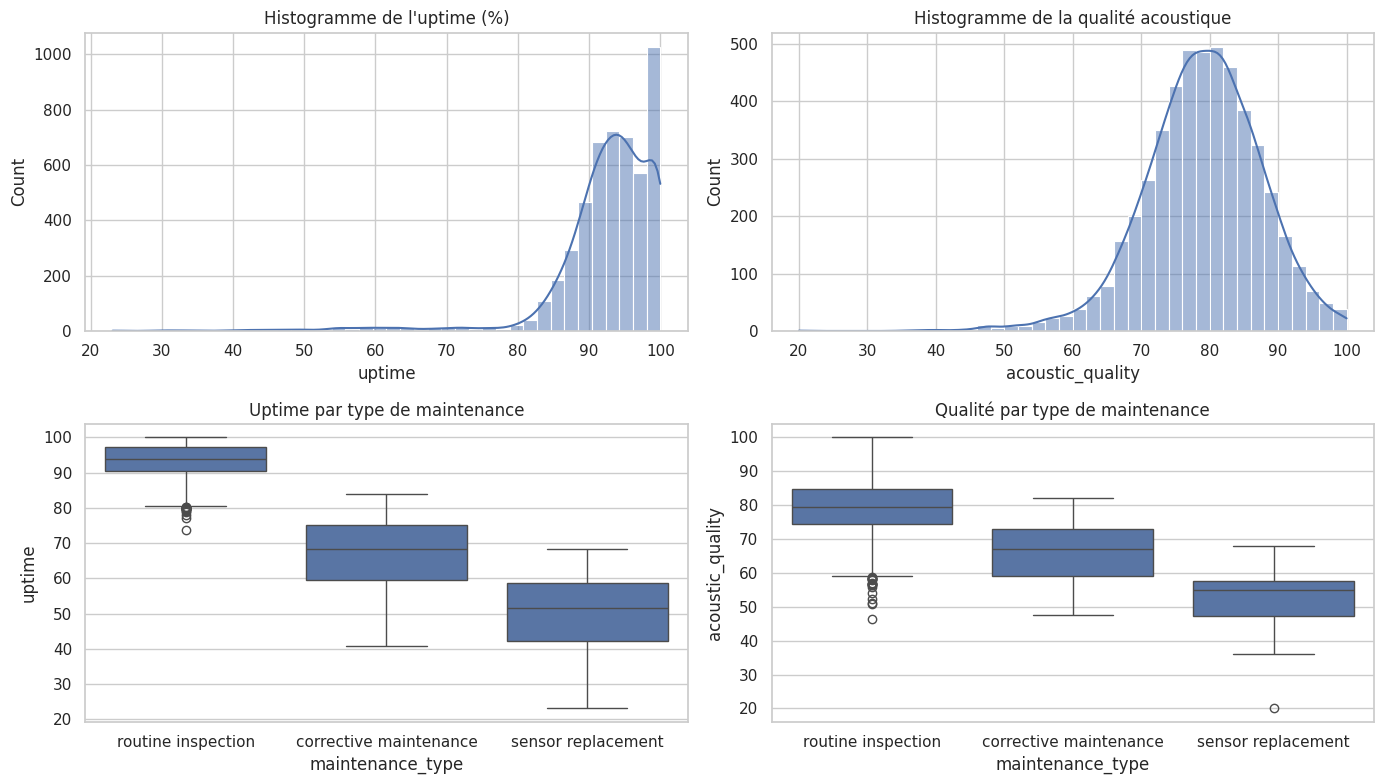


Corrélations uptime ~ qualité
  toutes les lignes                Pearson = +0.317 | Spearman = +0.084
  inspections de routine seules    Pearson = -0.005 | Spearman = -0.004

Asymétrie uptime : -3.38 | qualité : -0.52


In [ ]:
num = ["uptime", "acoustic_quality"]
print(dev[num].describe().round(1))
print("\nPar type de maintenance :"); print(dev.groupby("maintenance_type")[num].agg(["count", "mean", "std"]).round(1))

fig, ax = plt.subplots(2, 2, figsize=(14, 8))
sns.histplot(dev.uptime, bins=40, kde=True, ax=ax[0, 0]); ax[0, 0].set_title("Histogramme de l'uptime (%)")
sns.histplot(dev.acoustic_quality, bins=40, kde=True, ax=ax[0, 1]); ax[0, 1].set_title("Histogramme de la qualité acoustique")
sns.boxplot(data=dev, x="maintenance_type", y="uptime", ax=ax[1, 0]); ax[1, 0].set_title("Uptime par type de maintenance")
sns.boxplot(data=dev, x="maintenance_type", y="acoustic_quality", ax=ax[1, 1]); ax[1, 1].set_title("Qualité par type de maintenance")
plt.tight_layout(); plt.show()

routine = dev[dev.maintenance_type == "routine inspection"]
print("\nCorrélations uptime ~ qualité")
for nom, df in [("toutes les lignes", dev), ("inspections de routine seules", routine)]:
    print(f"  {nom:<32} Pearson = {df.uptime.corr(df.acoustic_quality):+.3f} | Spearman = {df.uptime.corr(df.acoustic_quality, method='spearman'):+.3f}")
print("\nAsymétrie uptime :", round(dev.uptime.skew(), 2), "| qualité :", round(dev.acoustic_quality.skew(), 2))

### Interprétation (cellule 5)

- La corrélation globale est entièrement produite par les mois de panne (quand l'appareil tombe, uptime et qualité s'effondrent ensemble). Dans le fonctionnement normal, les deux variables sont indépendantes.



## Cellule 6 — Pannes : sont-elles aléatoires ?


Pannes par site (distribution) :
count    64.0
mean      3.0
std       4.6
min       0.0
25%       1.0
50%       2.0
75%       3.0
max      28.0
Name: n_fault, dtype: float64

Top 8 des sites par nombre de pannes :
           n_fault  n_sensor       site_category                                region
site_code                                                                             
AVL-TRP         28        26  orchard monitoring  Eastern Avelora Agricultural Cluster
KNT-CHP         27        26  habitat monitoring                 Kintara Karst Cluster
AVL-NFR          4         0  orchard monitoring  Eastern Avelora Agricultural Cluster
KNT-LUM          4         0     cave monitoring                 Kintara Karst Cluster
KNT-DMJ          4         0  habitat monitoring                 Kintara Karst Cluster
TMB-PEL          4         0  habitat monitoring               Tembara Coastal Cluster
KNT-WUQ          4         0  habitat monitoring                 Kintara Karst Cluster
KN

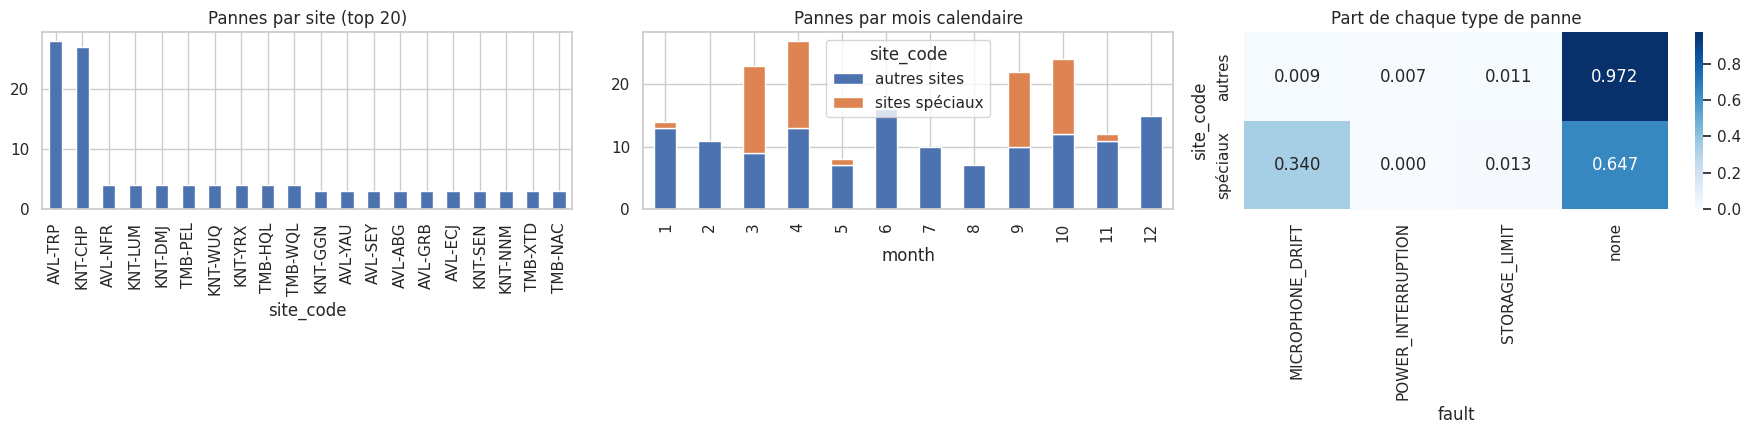

In [ ]:
SPECIAL = None   # sera défini plus bas
fault_site = dev.groupby("site_code").agg(n_fault=("fault", lambda x: (x != "none").sum()),
                                           n_sensor=("maintenance_type", lambda x: (x == "sensor replacement").sum()))
fault_site = fault_site.join(sites.set_index("site_code")[["site_category", "region"]])
print("Pannes par site (distribution) :"); print(fault_site.n_fault.describe().round(1))
print("\nTop 8 des sites par nombre de pannes :"); print(fault_site.sort_values("n_fault", ascending=False).head(8))

SPECIAL = fault_site.index[fault_site.n_fault > 10].tolist()
print("\nSites 'spéciaux' (> 10 pannes) :", SPECIAL)

print("\nRemplacements de capteur (sensor replacement) :", (dev.maintenance_type == "sensor replacement").sum(),
      "| dont sur ces sites :", ((dev.maintenance_type == "sensor replacement") & dev.site_code.isin(SPECIAL)).sum())

others = dev[~dev.site_code.isin(SPECIAL) & (dev.fault != "none")]
print("\nPannes des 62 autres sites :", len(others), "| par site :", round(len(others) / 62, 2))
for c in ["provider", "device_model", "region", "site_category"]:
    p = stats.chi2_contingency(pd.crosstab(others[c], others.fault))[1]
    print(f"  chi2 {c:<14} x type de panne : p = {p:.3f}")
mc = others.month.value_counts().reindex(range(1, 13), fill_value=0)
print("  chi2 pannes par mois (uniforme ?) : p = %.3f" % stats.chisquare(mc)[1])

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
fault_site.sort_values("n_fault", ascending=False).n_fault.head(20).plot.bar(ax=ax[0]); ax[0].set_title("Pannes par site (top 20)")
cnt = dev[dev.fault != "none"].groupby(["month", dev.site_code.isin(SPECIAL).map({True: "sites spéciaux", False: "autres sites"})]).size().unstack(fill_value=0)
cnt.plot.bar(stacked=True, ax=ax[1]); ax[1].set_title("Pannes par mois calendaire")
sns.heatmap(pd.crosstab(dev.site_code.isin(SPECIAL).map({True: "spéciaux", False: "autres"}), dev.fault, normalize="index"), annot=True, fmt=".3f", cmap="Blues", ax=ax[2])
ax[2].set_title("Part de chaque type de panne")
plt.tight_layout(); plt.show()

### Interprétation (cellule 6)

- La structure du dataset est « 62 sites normaux + 2 sites spéciaux ». Les pannes sont un bruit homogène sur les sites normaux, et un phénomène à part sur les deux autres.
- KNT-CHP est le site déjà détecté comme atypique au notebook 1 (karst non classé caverne, altitude maximale). AVL-TRP est un vergerde la région Avelora, sans lien visible dans la table 1.


## Cellule 7 — Séries temporelles par région


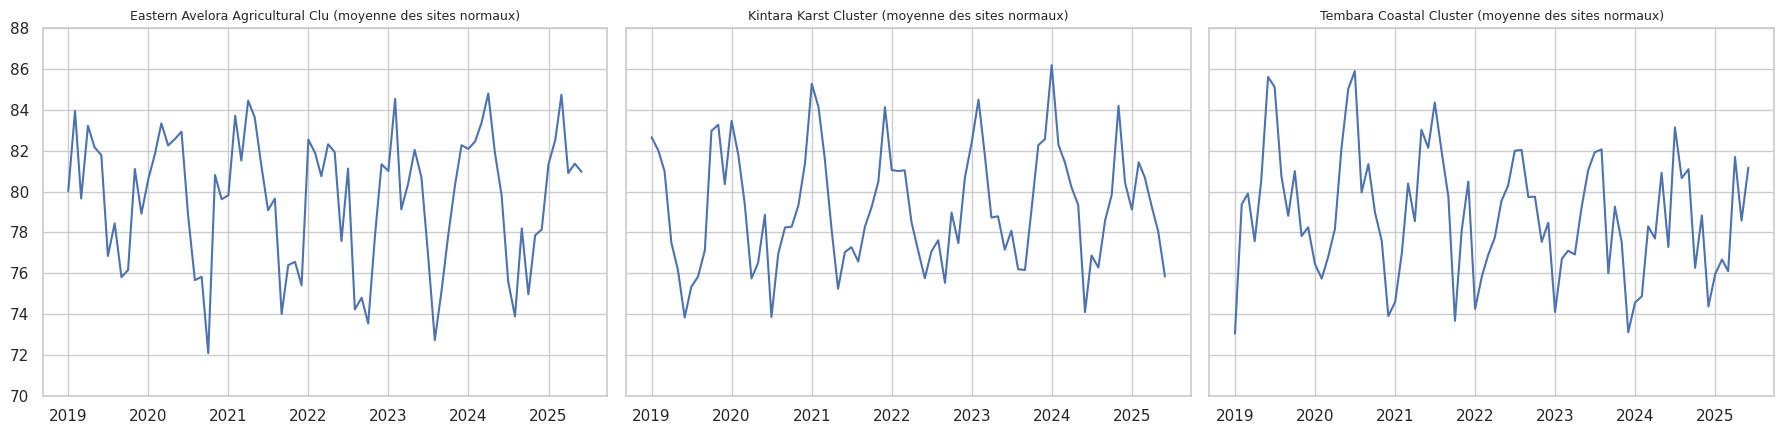

Profil saisonnier moyen par région (qualité acoustique, sites normaux) :
ym                                      1     2     3     4     5     6     7     8     9     10    11    12
Eastern Avelora Agricultural Cluster  81.1  83.0  81.8  82.6  82.2  80.7  78.1  75.8  75.6  75.2  79.1  79.3
Kintara Karst Cluster                 82.9  82.5  81.0  78.3  77.3  76.1  76.4  76.6  77.3  79.7  81.2  81.6
Tembara Coastal Cluster               74.7  76.6  77.9  78.3  80.6  81.8  83.7  81.2  79.5  78.2  77.9  76.4


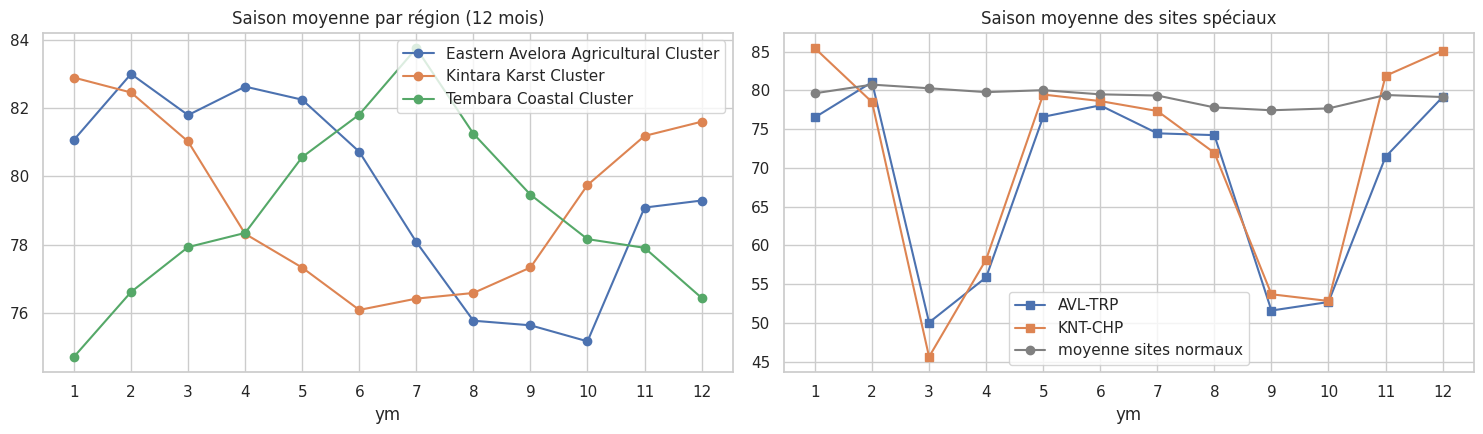

In [ ]:
Q = dev.pivot(index="ym", columns="site_code", values="acoustic_quality")       # 78 mois x 64 sites
U = dev.pivot(index="ym", columns="site_code", values="uptime")
site_region = sites.set_index("site_code").region
site_cat = sites.set_index("site_code").site_category
NORMAL = [c for c in Q.columns if c not in SPECIAL]

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for a, (reg, cols) in zip(ax, site_region[NORMAL].groupby(site_region[NORMAL]).groups.items()):
    m = Q[list(cols)].mean(axis=1)
    a.plot(m.index.to_timestamp(), m.values); a.set_title(reg[:32] + " (moyenne des sites normaux)", fontsize=9)
    a.set_ylim(70, 88)
plt.tight_layout(); plt.show()

prof_reg = pd.DataFrame({reg: Q[list(cols)].groupby(Q.index.month).mean().mean(axis=1) for reg, cols in site_region[NORMAL].groupby(site_region[NORMAL]).groups.items()})
print("Profil saisonnier moyen par région (qualité acoustique, sites normaux) :"); print(prof_reg.T.round(1))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
prof_reg.plot(marker="o", ax=ax[0]); ax[0].set_title("Saison moyenne par région (12 mois)"); ax[0].set_xticks(range(1, 13))
for sc in SPECIAL:
    Q[sc].groupby(Q.index.month).mean().plot(marker="s", ax=ax[1], label=sc)
Q[NORMAL].mean(axis=1).groupby(Q.index.month).mean().plot(marker="o", ax=ax[1], label="moyenne sites normaux", color="gray")
ax[1].legend(); ax[1].set_title("Saison moyenne des sites spéciaux"); ax[1].set_xticks(range(1, 13))
plt.tight_layout(); plt.show()

### Interprétation (cellule 7)

- *H-G :* les deux sites spéciaux ont un défaut calé sur le calendrier, donc probablement systémique (planning de maintenance ? campagne d'étalonnage ? facteur commun inconnu).
- *H-H :* le cycle régional de la qualité acoustique reflète un régime climatique (type saison des pluies) propre à chaque région. Rien ne le démontre avec cette seule table.

## Cellule 8 — Auto-corrélation (ACF) et décomposition


Avelora (normaux)    ACF(6) = -0.57 | ACF(12) = +0.59 | ACF(24) = +0.45
Kintara (normaux)    ACF(6) = -0.66 | ACF(12) = +0.58 | ACF(24) = +0.47
Tembara (normaux)    ACF(6) = -0.56 | ACF(12) = +0.55 | ACF(24) = +0.39
AVL-TRP              ACF(6) = +0.61 | ACF(12) = +0.51 | ACF(24) = +0.43
KNT-CHP              ACF(6) = +0.55 | ACF(12) = +0.60 | ACF(24) = +0.51


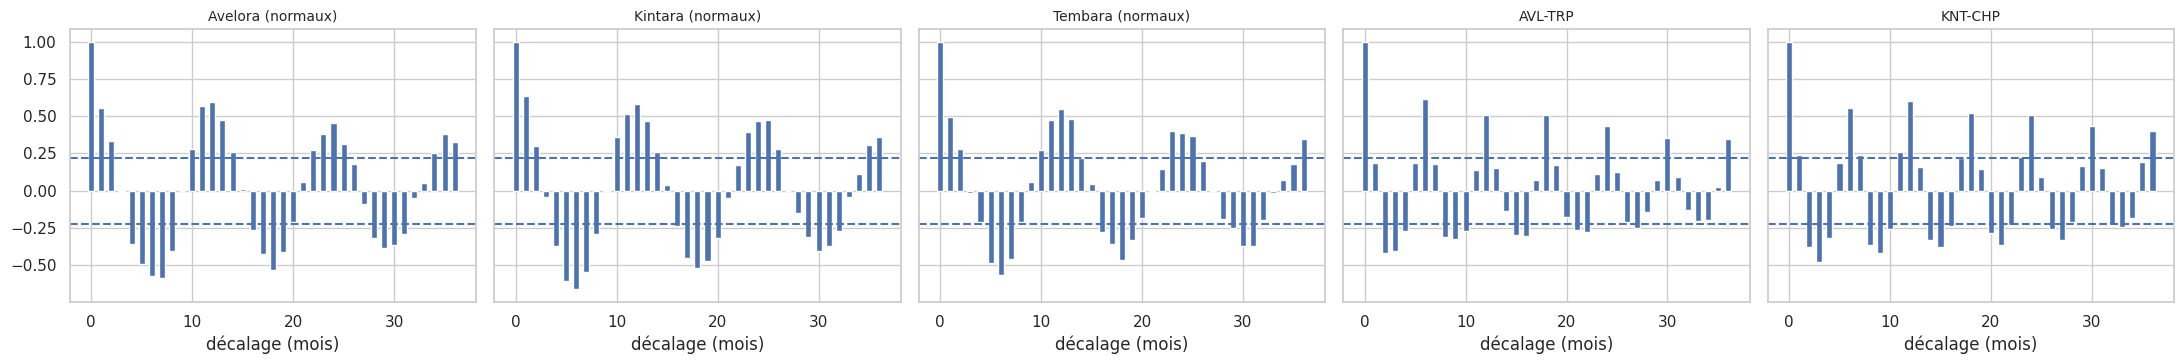

Tembara (normaux)    écart-type : série 3.00 | saison 2.47 | résidu 1.55
AVL-TRP              écart-type : série 13.74 | saison 11.82 | résidu 6.95


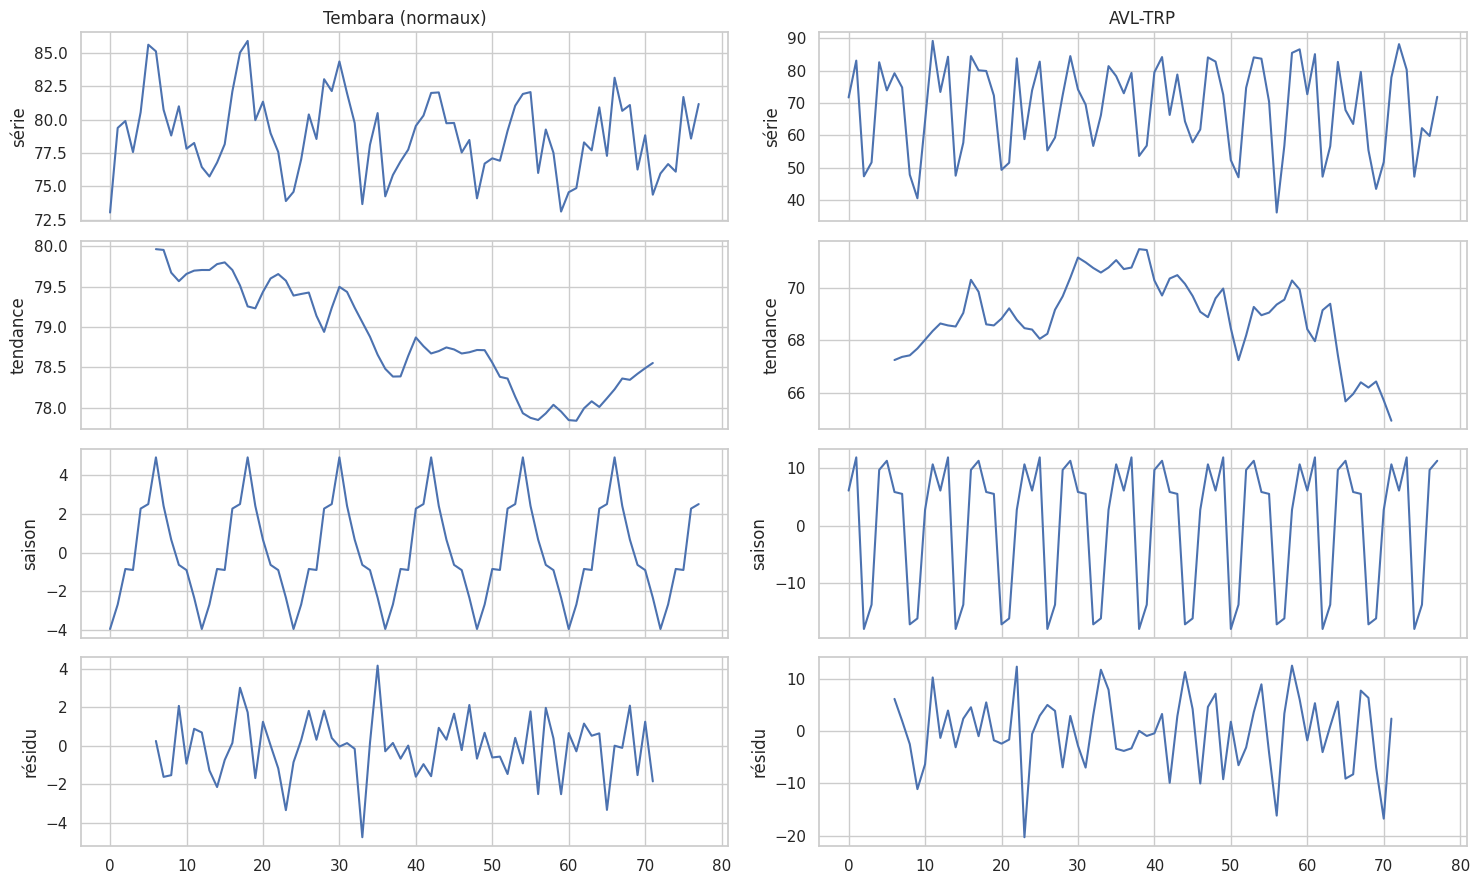

STL (statsmodels) disponible : écart-type du résidu 7.78


In [ ]:
def acf(x, nlags=36):
    x = np.asarray(x, float) - np.mean(x)
    den = (x ** 2).sum()
    return np.array([1.0] + [(x[:-k] * x[k:]).sum() / den for k in range(1, nlags + 1)])

def classical_decomposition(series, period=12):
    """Décomposition classique (cours 5) : tendance (moyenne mobile centrée 2xperiod), saison, résidu."""
    s = pd.Series(np.asarray(series, float))
    tr = s.rolling(period, center=True).mean()
    tr = (tr + tr.shift(-1)) / 2
    detr = s - tr
    seas_m = detr.groupby(np.arange(len(s)) % period).transform("mean")
    seas = seas_m - seas_m.mean()
    return tr, seas, s - tr - seas

series = {"Avelora (normaux)": Q[[c for c in NORMAL if site_region[c].startswith("Eastern")]].mean(axis=1),
          "Kintara (normaux)": Q[[c for c in NORMAL if site_region[c].startswith("Kintara")]].mean(axis=1),
          "Tembara (normaux)": Q[[c for c in NORMAL if site_region[c].startswith("Tembara")]].mean(axis=1),
          SPECIAL[0]: Q[SPECIAL[0]], SPECIAL[1]: Q[SPECIAL[1]]}

n = len(Q); band = 1.96 / np.sqrt(n)
fig, ax = plt.subplots(1, 5, figsize=(22, 3.8), sharey=True)
for a, (name, s) in zip(ax, series.items()):
    r = acf(s.values, 36); a.bar(range(len(r)), r, width=.6); a.axhline(band, ls="--", c="b"); a.axhline(-band, ls="--", c="b")
    a.set_title(name, fontsize=10); a.set_xlabel("décalage (mois)")
    print(f"{name:<20} ACF(6) = {r[6]:+.2f} | ACF(12) = {r[12]:+.2f} | ACF(24) = {r[24]:+.2f}")
plt.tight_layout(); plt.show()

# Décomposition (Tembara normaux et site spécial) + STL si statsmodels est disponible
fig, ax = plt.subplots(4, 2, figsize=(15, 9), sharex="col")
for j, name in enumerate(["Tembara (normaux)", SPECIAL[0]]):
    tr, se, re = classical_decomposition(series[name].values)
    for i, (lab, v) in enumerate([("série", series[name].values), ("tendance", tr), ("saison", se), ("résidu", re)]):
        ax[i, j].plot(v); ax[i, j].set_ylabel(lab)
    ax[0, j].set_title(name)
    print(f"{name:<20} écart-type : série {np.nanstd(series[name].values):.2f} | saison {se.std():.2f} | résidu {np.nanstd(re):.2f}")
plt.tight_layout(); plt.show()

try:
    from statsmodels.tsa.seasonal import STL
    stl = STL(series[SPECIAL[0]].values, period=12, robust=True).fit()
    print("STL (statsmodels) disponible : écart-type du résidu", round(stl.resid.std(), 2))
except ImportError:
    print("statsmodels absent : STL ignoré (la décomposition classique suffit).")

### Interprétation (cellule 8)
 les deux sites spéciaux ne « s'usent » pas, ils sont soumis à un cycle semestriel fixe. Une usure irait en s'aggravant, ici chaque année recommence à l'identique .

## Cellule 9 — Anomalies temporelles : l'importance de la référence


(A) Fenêtre glissante 13 mois -> nb de mois signalés par site (top 6) :
AVL-BVM    4
KNT-GGN    4
AVL-MAR    3
AVL-ARU    3
KNT-JQG    3
KNT-DMJ    3
dtype: int64
Médiane sur les autres sites : 1.0 | total des 62 autres : 85

(B) Écart à son propre profil saisonnier -> mois signalés (top 6) :
site_code
KNT-DMJ    2
KNT-LUM    2
AVL-BWK    1
AVL-ECJ    1
AVL-YAU    1
KNT-CHP    1
dtype: int64

(C) Écart à la moyenne de la région (sites normaux) -> mois signalés (top 6) :
site_code
AVL-TRP    17
KNT-CHP    10
AVL-FNQ     2
KNT-DMJ     2
TMB-HQL     2
KNT-BME     1
dtype: int64


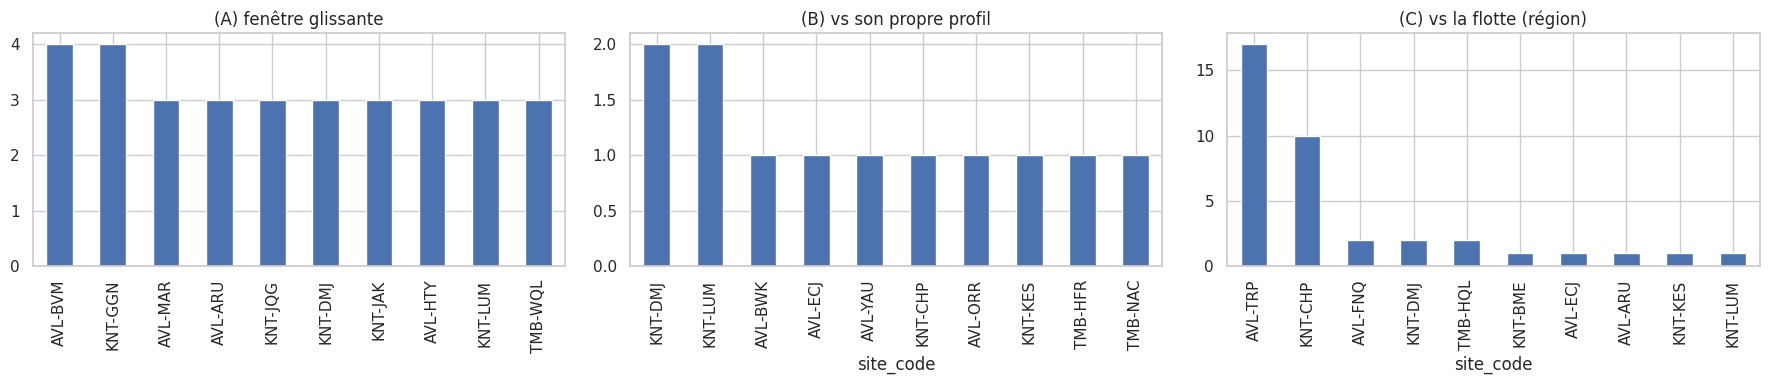

In [ ]:
def modified_z(x, ref=None):
    """Z-score modifié : 0,6745 (x - médiane) / MAD  (seuil usuel 3,5)."""
    x = np.asarray(x, float); med = np.nanmedian(x if ref is None else ref)
    mad = np.nanmedian(np.abs((x if ref is None else ref) - med))
    return 0.6745 * (x - med) / mad if mad > 0 else np.zeros_like(x)

# (A) Fenêtre glissante de 13 mois centrée (cours 5), appliquée à chaque site
def sliding_flags(s, win=13, thr=3.5):
    s = pd.Series(s.values, index=s.index); out = np.zeros(len(s), bool); half = win // 2
    for i in range(len(s)):
        w = s.values[max(0, i - half): i + half + 1]
        out[i] = abs(modified_z(np.array([s.values[i]]), ref=w)[0]) > thr
    return pd.Series(out, index=s.index)

flagsA = pd.DataFrame({c: sliding_flags(Q[c]) for c in Q.columns})
cntA = flagsA.sum().sort_values(ascending=False)
print("(A) Fenêtre glissante 13 mois -> nb de mois signalés par site (top 6) :"); print(cntA.head(6))
print("Médiane sur les autres sites :", cntA.drop(SPECIAL).median(), "| total des 62 autres :", cntA.drop(SPECIAL).sum())

# (B) Référence = ses propres moyennes mensuelles (anomalie vs son propre passé)
own = Q - Q.groupby(Q.index.month).transform("mean")
zB = own.apply(lambda c: pd.Series(modified_z(c.values), index=c.index))
cntB = (zB.abs() > 3.5).sum().sort_values(ascending=False)
print("\n(B) Écart à son propre profil saisonnier -> mois signalés (top 6) :"); print(cntB.head(6))

# (C) Référence = flotte : écart à la moyenne région x mois des sites NORMAUX
reg_month = Q[NORMAL].T.groupby(site_region[NORMAL]).mean().T     # 78 x 3
ref = pd.DataFrame({c: reg_month[site_region[c]] for c in Q.columns})
resid = Q - ref
pool = resid[NORMAL].to_numpy().ravel()                           # échelle commune : écarts des sites normaux
med, mad = np.median(pool), np.median(np.abs(pool - np.median(pool)))
zC = 0.6745 * (resid - med) / mad
cntC = (zC.abs() > 3.5).sum().sort_values(ascending=False)
print("\n(C) Écart à la moyenne de la région (sites normaux) -> mois signalés (top 6) :"); print(cntC.head(6))

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for a, (t, c) in zip(ax, [("(A) fenêtre glissante", cntA), ("(B) vs son propre profil", cntB), ("(C) vs la flotte (région)", cntC)]):
    c.head(10).plot.bar(ax=a); a.set_title(t)
plt.tight_layout(); plt.show()

### Interprétation (cellule 9)

- Le même jeu de données donne **trois réponses opposées** selon la référence. Un défaut régulier n'est pas détecté par les méthodes qui comparent un site à lui-même ou à son voisinage temporel : il est détecté seulement par comparaison à la flotte.


## Cellule 10 — Profils de sites : PCA, t-SNE, Isolation Forest, LOF, DBSCAN


           q_mean  q_std  u_mean  u_std  n_fault  season_amp  acf12  acf6       site_category                                region  elevation_m
site_code                                                                                                                                       
AVL-TRP     68.58  13.83   77.94  23.42       28       31.01   0.51  0.61  orchard monitoring  Eastern Avelora Agricultural Cluster        237.0
KNT-CHP     70.75  15.56   78.52  21.70       27       39.81   0.60  0.55  habitat monitoring                 Kintara Karst Cluster        418.8
AVL-NFR     79.68   9.32   93.14   6.77        4       13.21   0.10  0.00  orchard monitoring  Eastern Avelora Agricultural Cluster         26.4
KNT-LUM     77.94   7.45   91.16   8.67        4       11.50  -0.08 -0.24     cave monitoring                 Kintara Karst Cluster         25.0

Variance expliquée PCA : [0.75 0.12]
Poids des variables (PC1, PC2) :
             PC1   PC2
q_mean     -0.36 -0.01
q_std       0

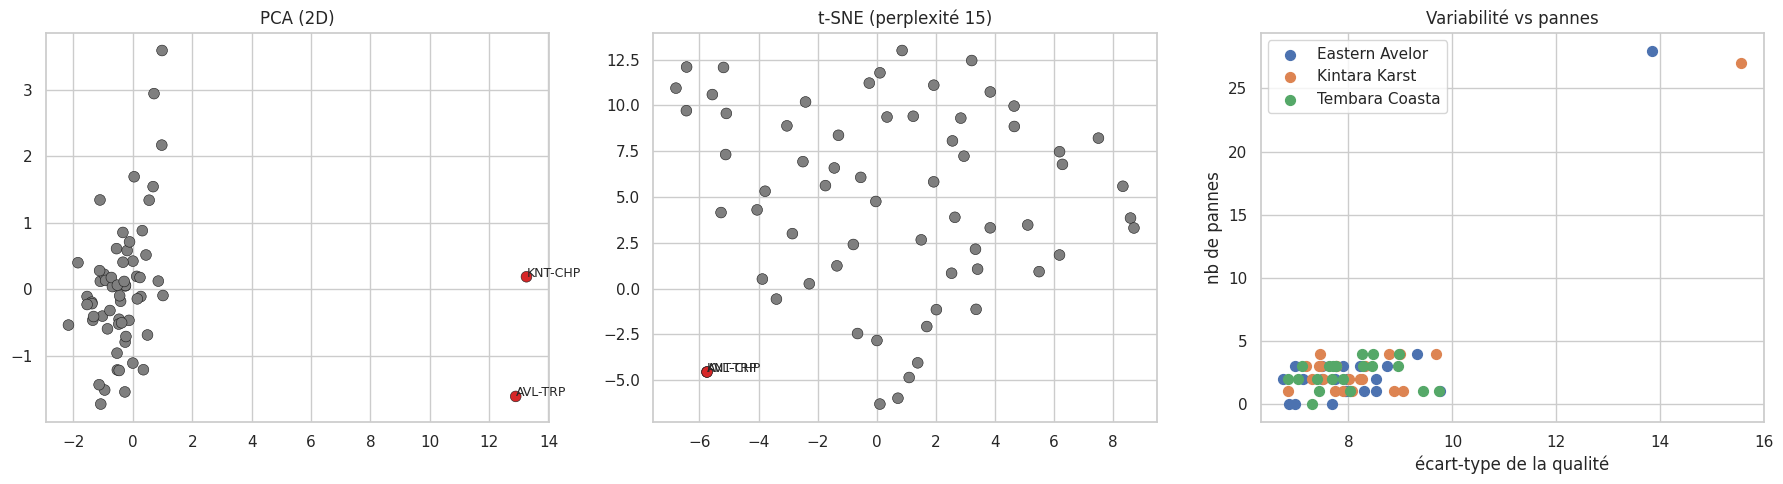


Sans les sites spéciaux - top 5 Isolation Forest : ['AVL-FNQ', 'TMB-GWP', 'KNT-LUM', 'KNT-DMJ', 'TMB-GZX']
Sans les sites spéciaux - top 5 LOF              : ['AVL-FNQ', 'KNT-LUM', 'TMB-GWP', 'TMB-HFR', 'KNT-YRX']


In [ ]:
t_idx = np.arange(len(Q))
feat = pd.DataFrame(index=Q.columns)
feat["q_mean"] = Q.mean(); feat["q_std"] = Q.std()
feat["u_mean"] = U.mean(); feat["u_std"] = U.std()
feat["n_fault"] = fault_site.n_fault
prof = Q.groupby(Q.index.month).mean().T                  # 64 x 12 : profil saisonnier
feat["season_amp"] = prof.max(axis=1) - prof.min(axis=1)
feat["acf12"] = [acf(Q[c].values, 12)[12] for c in Q.columns]
feat["acf6"] = [acf(Q[c].values, 6)[6] for c in Q.columns]
feat = feat.join(sites.set_index("site_code")[["site_category", "region", "elevation_m"]])
print(feat.sort_values("n_fault", ascending=False).head(4).round(2))

cols = ["q_mean", "q_std", "u_mean", "u_std", "n_fault", "season_amp", "acf12", "acf6"]
Z = StandardScaler().fit_transform(feat[cols])

# --- Réduction de dimension ---
pca = PCA(n_components=2, random_state=0).fit(Z); P2 = pca.transform(Z)
print("\nVariance expliquée PCA :", pca.explained_variance_ratio_.round(2))
print("Poids des variables (PC1, PC2) :"); print(pd.DataFrame(pca.components_.T, index=cols, columns=["PC1", "PC2"]).round(2))
T2 = TSNE(n_components=2, perplexity=15, init="pca", random_state=0).fit_transform(Z)

# --- Anomalies multivariées ---
iso = IsolationForest(n_estimators=300, contamination=0.05, random_state=0).fit(Z); feat["iso"] = -iso.score_samples(Z)
lof = LocalOutlierFactor(n_neighbors=8).fit(Z); feat["lof"] = -lof.negative_outlier_factor_
print("\nTop 5 Isolation Forest :", feat.nlargest(5, "iso").index.tolist())
print("Top 5 LOF              :", feat.nlargest(5, "lof").index.tolist())

# --- Clustering ---
db = DBSCAN(eps=2.2, min_samples=4).fit(Z); feat["dbscan"] = db.labels_
print("DBSCAN (eps=2.2, min_samples=4) :", pd.Series(db.labels_).value_counts().to_dict(), "| bruit :", feat.index[db.labels_ == -1].tolist())
km = KMeans(2, n_init=10, random_state=0).fit(Z); feat["kmeans2"] = km.labels_
print("K-means k=2 :", feat.groupby("kmeans2").size().to_dict(), "| sites du petit groupe :", feat.index[feat.kmeans2 == feat.kmeans2.value_counts().idxmin()].tolist())

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, (XY, t) in zip(ax[:2], [(P2, "PCA (2D)"), (T2, "t-SNE (perplexité 15)")]):
    a.scatter(XY[:, 0], XY[:, 1], c=np.where(feat.index.isin(SPECIAL), "#d62728", "#7f7f7f"), s=60, edgecolor="k", lw=.4)
    for sc in SPECIAL: i = list(feat.index).index(sc); a.annotate(sc, XY[i], fontsize=9)
    a.set_title(t)
for r, g in feat.groupby("region"): ax[2].scatter(g.q_std, g.n_fault, label=r[:14], s=50)
ax[2].set_xlabel("écart-type de la qualité"); ax[2].set_ylabel("nb de pannes"); ax[2].legend(); ax[2].set_title("Variabilité vs pannes")
plt.tight_layout(); plt.show()

# Sans les 2 sites spéciaux : reste-t-il d'autres anomalies ?
fN = feat.loc[NORMAL]; ZN = StandardScaler().fit_transform(fN[cols])
isoN = IsolationForest(n_estimators=300, contamination=0.05, random_state=0).fit(ZN)
lofN = LocalOutlierFactor(n_neighbors=8).fit(ZN)
print("\nSans les sites spéciaux - top 5 Isolation Forest :", fN.assign(s=-isoN.score_samples(ZN)).nlargest(5, "s").index.tolist())
print("Sans les sites spéciaux - top 5 LOF              :", fN.assign(s=-lofN.negative_outlier_factor_).nlargest(5, "s").index.tolist())

### Interprétation (cellule 10)

- La structure est binaire : 62 sites homogènes et 2 sites très différents. Les multiples algorithmes ne se contredisent pas : le résultat est robuste.
- Les sites secondaires (AVL-FNQ: qualité moyenne la plus basse des sites normaux, 76,4, mais uptime élevé avec 16 mois à 100 % ; TMB-GWP: deuxième qualité la plus basse, 77,1, avec un écart-type élevé) sont simplement en bout de distribution ; rien ne justifie de les considérer comme « anormaux ».


## Cellule 11 — Clustering des profils saisonniers


K-means sur les profils saisonniers (62 sites normaux) :
  k=3 : ARI vs région = 0.77 | ARI vs type de site = 0.05
  k=4 : ARI vs région = 0.81 | ARI vs type de site = 0.05
  k=5 : ARI vs région = 0.62 | ARI vs type de site = 0.04

Tableau croisé k=3 x région :
col_0  Eastern Avelora Agricultural Cluster  Kintara Karst Cluster  Tembara Coastal Cluster
row_0                                                                                      
0                                         1                     18                        0
1                                         0                      0                       19
2                                        20                      3                        1

Contraste (déc-fév) - (juin-août) par région (sites normaux) :
                                      mean  std
region                                         
Eastern Avelora Agricultural Cluster   2.9  2.2
Kintara Karst Cluster                  6.0  2.7
Tembara Coastal Cluste

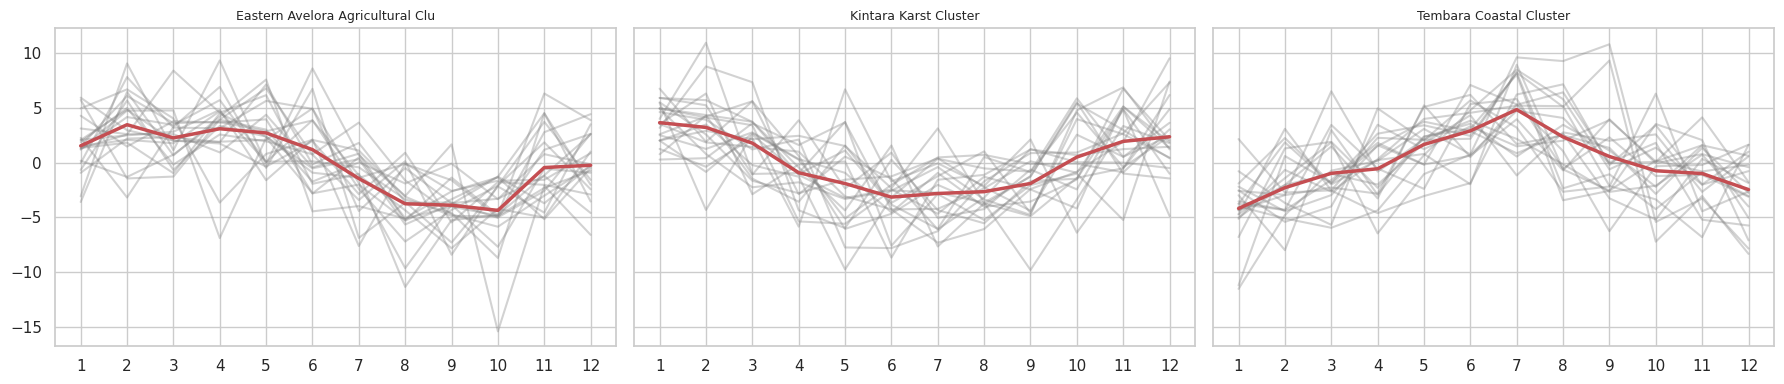

In [ ]:
# Profil saisonnier de chaque site, centré (on retire sa moyenne : on compare les FORMES)
prof_c = prof.sub(prof.mean(axis=1), axis=0)
nm = [c for c in prof_c.index if c not in SPECIAL]
Xp = prof_c.loc[nm].values
reg_lab = site_region[nm].values; cat_lab = site_cat[nm].values

print("K-means sur les profils saisonniers (62 sites normaux) :")
for k in [3, 4, 5]:
    lab = KMeans(k, n_init=10, random_state=0).fit(Xp).labels_
    print(f"  k={k} : ARI vs région = {adjusted_rand_score(reg_lab, lab):.2f} | ARI vs type de site = {adjusted_rand_score(cat_lab, lab):.2f}")

lab3 = KMeans(3, n_init=10, random_state=0).fit(Xp).labels_
print("\nTableau croisé k=3 x région :"); print(pd.crosstab(lab3, reg_lab))

# Contraste hiver/été : moyenne (déc-jan-fév) moins moyenne (juin-juil-août)
season_contrast = prof[[12, 1, 2]].mean(axis=1) - prof[[6, 7, 8]].mean(axis=1)
print("\nContraste (déc-fév) - (juin-août) par région (sites normaux) :")
print(season_contrast[nm].groupby(site_region[nm]).agg(["mean", "std"]).round(1))

fig, ax = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for a, (reg, g) in zip(ax, pd.Series(nm).groupby(site_region[nm].values)):
    for c in g: a.plot(range(1, 13), prof_c.loc[c].values, c="gray", alpha=.35)
    a.plot(range(1, 13), prof_c.loc[list(g)].mean().values, c="r", lw=2.5); a.set_title(reg[:32], fontsize=9); a.set_xticks(range(1, 13))
plt.tight_layout(); plt.show()

### Interprétation (cellule 11)

- La saisonnalité de la qualité acoustique est un effet de région, pas de type de site** : une caverne, un verger et un habitat d'une même région ont le même cycle. Cela affaiblit toute idée d'une « signature saisonnière caverne ».


## Cellule 12 — Autocorrélation spatiale (I de Moran)


     échantillon         variable  I de Moran  I attendu      p
0     tous sites           q_mean      -0.001     -0.016  0.983
1  sites normaux           q_mean       0.047     -0.016  0.485
2     tous sites          n_fault      -0.027     -0.016  0.615
3  sites normaux          n_fault       0.044     -0.016  0.565
4     tous sites  season_contrast       0.790     -0.016  0.001
5  sites normaux  season_contrast       0.794     -0.016  0.001
6     tous sites           u_mean      -0.024     -0.016  0.629
7  sites normaux           u_mean       0.110     -0.016  0.122

Par région (sites normaux), contraste saisonnier :
  Kintara Karst Cluster          I = -0.031 | p = 0.812
  Eastern Avelora Agricultural C I = +0.036 | p = 0.811
  Tembara Coastal Cluster        I = -0.047 | p = 0.740


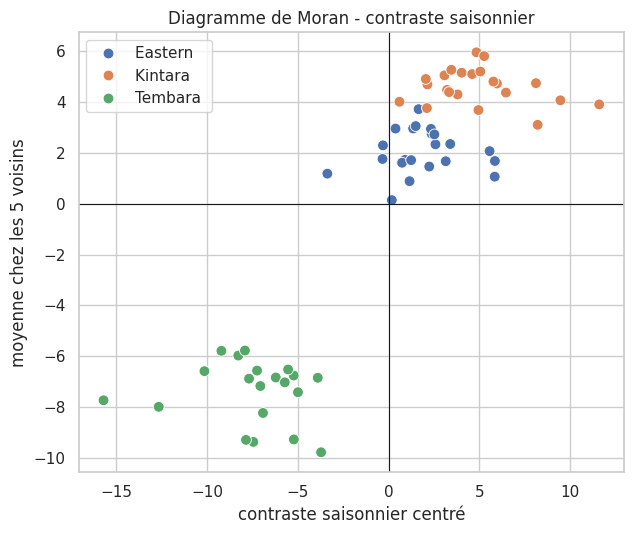

In [ ]:
R_EARTH = 6371.0
rad = np.radians(sites.set_index("site_code").loc[feat.index, ["latitude", "longitude"]].to_numpy())
Dk = haversine_distances(rad) * R_EARTH

def knn_weights(Dm, k=5):
    n = len(Dm); W = np.zeros((n, n)); Dd = Dm + np.eye(n) * 1e9
    for i in range(n): W[i, np.argsort(Dd[i])[:k]] = 1
    return W

def morans_I(y, W, n_perm=999, seed=0):
    y = np.asarray(y, float); n = len(y); z = y - y.mean()
    I_of = lambda zz: n / (zz ** 2).sum() * (W * np.outer(zz, zz)).sum() / W.sum()
    obs = I_of(z); rng = np.random.default_rng(seed)
    sims = np.array([I_of(rng.permutation(z)) for _ in range(n_perm)])
    return obs, -1 / (n - 1), (1 + (np.abs(sims) >= abs(obs)).sum()) / (n_perm + 1)

W = knn_weights(Dk, 5)
feat["season_contrast"] = season_contrast
res = []
for var in ["q_mean", "n_fault", "season_contrast", "u_mean"]:
    I, EI, p = morans_I(feat[var], W); res.append(("tous sites", var, round(I, 3), round(EI, 3), round(p, 3)))
    nm_idx = [list(feat.index).index(c) for c in NORMAL]
    I, EI, p = morans_I(feat.loc[NORMAL, var], knn_weights(Dk[np.ix_(nm_idx, nm_idx)], 5)); res.append(("sites normaux", var, round(I, 3), round(EI, 3), round(p, 3)))
print(pd.DataFrame(res, columns=["échantillon", "variable", "I de Moran", "I attendu", "p"]))

print("\nPar région (sites normaux), contraste saisonnier :")
for reg in sites.region.unique():
    idx = [list(feat.index).index(c) for c in NORMAL if site_region[c] == reg]
    I, EI, p = morans_I(feat.iloc[idx].season_contrast, knn_weights(Dk[np.ix_(idx, idx)], 5)); print(f"  {reg[:30]:<30} I = {I:+.3f} | p = {p:.3f}")

z = (feat.season_contrast - feat.season_contrast.mean()).to_numpy()
lag = (W / W.sum(axis=1, keepdims=True)) @ z
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.scatterplot(x=z, y=lag, hue=site_region[feat.index].str[:8].values, s=60, ax=ax); ax.axhline(0, c="k", lw=.8); ax.axvline(0, c="k", lw=.8)
ax.set_xlabel("contraste saisonnier centré"); ax.set_ylabel("moyenne chez les 5 voisins"); ax.set_title("Diagramme de Moran - contraste saisonnier")
plt.tight_layout(); plt.show()

### Interprétation (cellule 12)
 la géographie n'agit qu'au niveau de la région (la phase du cycle saisonnier est régionale) ; à l'échelle locale, les sites voisins ne se ressemblent pas plus que des sites pris au hasard. Les pannes ne sont pas organisées dans l'espace .


## Cellule 13 — Tendances à long terme et tests multiples


Sites avec la plus forte tendance (pente en points de qualité par an) :
         pente_par_an      p                                region            category
site                                                                                  
TMB-SXP        -1.189  0.006               Tembara Coastal Cluster  habitat monitoring
TMB-HQL        -1.223  0.009               Tembara Coastal Cluster  orchard monitoring
KNT-YRG         1.082  0.014                 Kintara Karst Cluster  habitat monitoring
TMB-NAC        -1.077  0.021               Tembara Coastal Cluster     cave monitoring
AVL-MAR         0.927  0.024  Eastern Avelora Agricultural Cluster  orchard monitoring
AVL-SEY        -0.711  0.058  Eastern Avelora Agricultural Cluster  habitat monitoring
KNT-CYP        -0.683  0.078                 Kintara Karst Cluster     cave monitoring

Nombre de p < 0,05 : 5 | attendu par hasard sur 64 sites : 3.2
Plus petit q (BH) : 0.3 -> aucun site n'est significatif après correction

Pente 

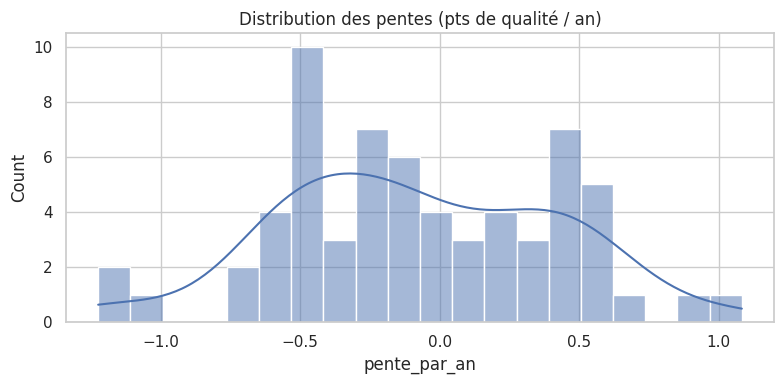

In [ ]:
# Tendance sur la série désaisonnalisée de chaque site (son propre profil mensuel retiré)
own = Q - Q.groupby(Q.index.month).transform("mean")
tt = np.arange(len(Q))
rows = []
for c in Q.columns:
    lr = stats.linregress(tt, own[c].values); rows.append((c, lr.slope * 12, lr.pvalue))
trend = pd.DataFrame(rows, columns=["site", "pente_par_an", "p"]).set_index("site")
trend["region"] = site_region; trend["category"] = site_cat
print("Sites avec la plus forte tendance (pente en points de qualité par an) :"); print(trend.sort_values("p").head(7).round(3))
print("\nNombre de p < 0,05 :", (trend.p < .05).sum(), "| attendu par hasard sur 64 sites :", round(.05 * 64, 1))

# Correction de Benjamini-Hochberg (contrôle du taux de fausses découvertes)
order = np.argsort(trend.p.values); m = len(trend)
q = np.empty(m); prev = 1.0
for rank, i in reversed(list(enumerate(order, start=1))):
    prev = min(prev, trend.p.values[i] * m / rank); q[i] = prev
trend["q_BH"] = q
print(
    "Plus petit q (BH) :", round(trend.q_BH.min(), 2),
    "-> aucun site n'est significatif après correction"
    if trend.q_BH.min() > 0.05
    else "-> au moins un site significatif"
)

print("\nPente moyenne par région :"); print(trend.groupby("region").pente_par_an.agg(["mean", "std", "count"]).round(2))
sl = trend.drop(SPECIAL)
tem = sl[sl.region.str.startswith("Tembara")].pente_par_an; oth = sl[~sl.region.str.startswith("Tembara")].pente_par_an
print("Tembara vs reste : t-test p = %.3f | Mann-Whitney p = %.3f" % (stats.ttest_ind(tem, oth, equal_var=False)[1], stats.mannwhitneyu(tem, oth)[1]))

# Comparaison à la loi attendue du bruit
se = (own.std() * 12 / np.sqrt(((tt - tt.mean()) ** 2).sum())).mean()
print("Erreur standard théorique d'une pente (pts/an) :", round(se, 2), "| écart-type observé des pentes :", round(trend.pente_par_an.std(), 2))
fig, ax = plt.subplots(figsize=(8, 4)); sns.histplot(trend.pente_par_an, bins=20, kde=True, ax=ax); ax.set_title("Distribution des pentes (pts de qualité / an)")
plt.tight_layout(); plt.show()

### Interprétation (cellule 13)

- Aucune tendance individuelle n'est démontrée. Se baser sur « TMB-NAC baisse de 1 point par an » serait une erreur classique de comparaisons multiples.


## Cellule 14 — Règles d'association (Apriori)




In [ ]:
ev = dev[dev.maintenance_type != "routine inspection"].copy()
ev["cat"] = ev.site_category.str.split().str[0]
ev["items"] = ev.apply(lambda r: {f"fault={r['fault']}", f"type={r['maintenance_type']}", f"prov={r['provider'][-1]}", f"model={r['device_model']}",
                                  f"region={r['region'][:3]}", f"cat={r['cat']}", f"month={r['month']:02d}"}, axis=1)
T = list(ev["items"]); N = len(T)
print("Transactions (site-mois non routiniers) :", N)

def support(S): return sum(1 for t in T if S <= t) / N

def apriori(min_support=0.2):
    items = sorted(set().union(*T)); cur = [frozenset([i]) for i in items if support({i}) >= min_support]
    freq = {f: support(f) for f in cur}; k = 2
    while cur:
        cand = {a | b for a in cur for b in cur if len(a | b) == k}
        cand = {c for c in cand if all(frozenset(x) in freq for x in itertools.combinations(c, k - 1))}   # élagage (anti-monotonie)
        cur = [c for c in cand if support(c) >= min_support]; freq.update({c: support(c) for c in cur}); k += 1
    return freq

freq = apriori(0.2)
print("Itemsets fréquents (support >= 0,2) :", len(freq))

rules = []
for f, sup in freq.items():
    if len(f) < 2: continue
    for r in range(1, len(f)):
        for a in itertools.combinations(f, r):
            a = frozenset(a); b = f - a; conf = sup / freq[a]
            rules.append((" & ".join(sorted(a)), " & ".join(sorted(b)), sup, conf, conf / freq[b], sup - freq[a] * freq[b]))
rules = pd.DataFrame(rules, columns=["si", "alors", "support", "confidence", "lift", "leverage"])
print("\nRègles avec confidence >= 0,9, triées par lift (top 12) :")
print(rules[rules.confidence >= .9].sort_values(["lift", "support"], ascending=False).head(12).round(2).to_string(index=False))

print("\nCalendrier des événements (part des mois non routiniers) :")
print(ev.month.value_counts(normalize=True).sort_index().round(2).to_dict())

Transactions (site-mois non routiniers) : 189
Itemsets fréquents (support >= 0,2) : 49

Règles avec confidence >= 0,9, triées par lift (top 12) :
                                              si                                     alors  support  confidence  lift  leverage
                         type=sensor replacement fault=MICROPHONE_DRIFT & model=3 & prov=1     0.28        1.00  3.50      0.20
       fault=MICROPHONE_DRIFT & model=3 & prov=1                   type=sensor replacement     0.28        0.96  3.50      0.20
                         type=sensor replacement           fault=MICROPHONE_DRIFT & prov=1     0.28        1.00  3.15      0.19
               model=3 & type=sensor replacement           fault=MICROPHONE_DRIFT & prov=1     0.28        1.00  3.15      0.19
                            model=3 & region=Eas                               cat=orchard     0.20        0.97  3.07      0.14
                         type=sensor replacement                          model=3 & pr

### Interprétation (cellule 14)
La règle est vraie mais circulaire : tous les remplacements de capteur sont sur deux sites qui partagent le même fournisseur (ECO-SERVICE-1) et le même modèle (3).



## Cellule 15 — Séquences d'événements (graphe, Heuristic Miner)


Transitions des sites spéciaux : {('R', 'R'): 72, ('R', 'S'): 26, ('S', 'S'): 26, ('S', 'R'): 24, ('S', 'C'): 2, ('C', 'R'): 3, ('R', 'C'): 1}
Transitions des autres sites    : {('R', 'R'): 4513, ('R', 'C'): 129, ('C', 'R'): 129, ('C', 'C'): 3}

Dépendance R => S (sites spéciaux) : 0.04 | S => R : -0.04


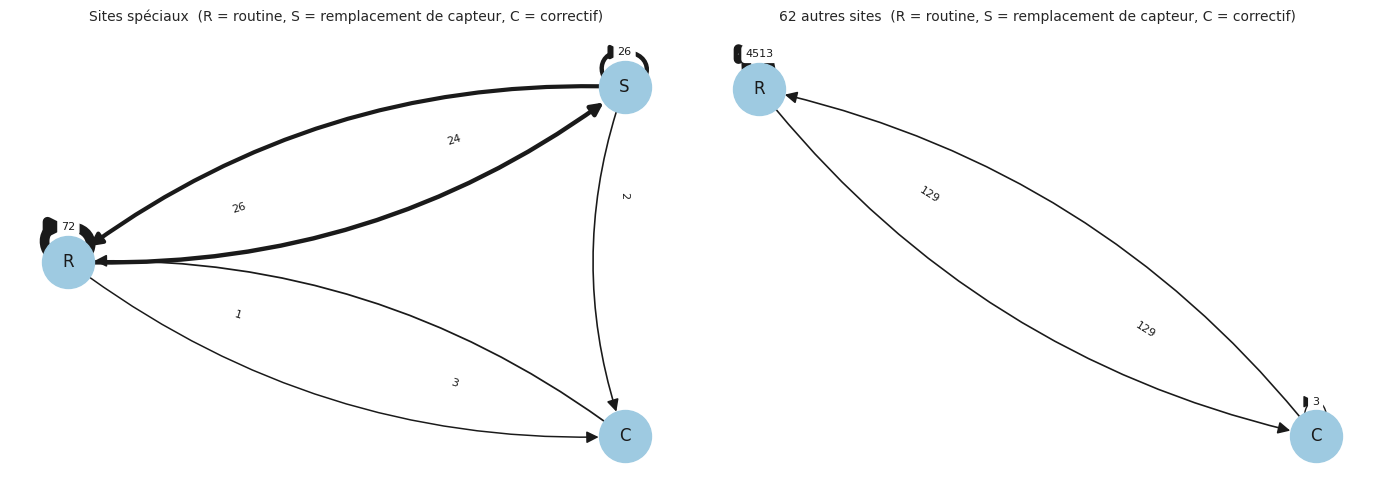


 AVL-TRP - séquence 2019-2020 : RRSSRRRRSSRRRRSSRRRRSSRR


In [ ]:
state = {"routine inspection": "R", "sensor replacement": "S", "corrective maintenance": "C"}
dev = dev.sort_values(["site_code", "start"]); dev["state"] = dev.maintenance_type.map(state)

def transitions(codes):
    cnt = {}
    for c in codes:
        s = dev.loc[dev.site_code == c, "state"].tolist()
        for a, b in zip(s[:-1], s[1:]): cnt[(a, b)] = cnt.get((a, b), 0) + 1
    return cnt

tr_sp = transitions(SPECIAL); tr_no = transitions(NORMAL)
print("Transitions des sites spéciaux :", tr_sp)
print("Transitions des autres sites    :", tr_no)

def dependency(cnt, a, b):               # Heuristic Miner (cours 4) : (|a>b| - |b>a|) / (|a>b| + |b>a| + 1)
    ab, ba = cnt.get((a, b), 0), cnt.get((b, a), 0)
    return (ab - ba) / (ab + ba + 1)
print("\nDépendance R => S (sites spéciaux) :", round(dependency(tr_sp, "R", "S"), 2), "| S => R :", round(dependency(tr_sp, "S", "R"), 2))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, (cnt, title) in zip(ax, [(tr_sp, "Sites spéciaux"), (tr_no, "62 autres sites")]):
    G = nx.DiGraph(); [G.add_edge(u, v, w=w) for (u, v), w in cnt.items()]
    pos = {"R": (0, 0), "S": (1.5, 0.8), "C": (1.5, -0.8)}
    nx.draw_networkx_nodes(G, pos, node_color="#9ecae1", node_size=1400, ax=a); nx.draw_networkx_labels(G, pos, ax=a)
    wmax = max(cnt.values())
    nx.draw_networkx_edges(G, pos, width=[1 + 6 * G[u][v]["w"] / wmax for u, v in G.edges], connectionstyle="arc3,rad=0.18", arrows=True, arrowsize=18, node_size=1400, ax=a)
    nx.draw_networkx_edge_labels(G, pos, edge_labels={(u, v): G[u][v]["w"] for u, v in G.edges}, label_pos=.3, font_size=8, ax=a)
    a.set_title(title + "  (R = routine, S = remplacement de capteur, C = correctif)", fontsize=10); a.axis("off")
plt.tight_layout(); plt.show()

# Séquence typique d'un site spécial
seq = dev.loc[dev.site_code == SPECIAL[0], ["ym", "state"]].set_index("ym").state
print("\n", SPECIAL[0], "- séquence 2019-2020 :", "".join(seq.iloc[:24]))

### Interprétation (cellule 15)

- La dépendance ≈ 0 ne signifie pas « pas de lien » : le motif est un cycle , et la mesure est conçue pour des ordres acycliques.
- le graphe confirme en une image que les deux sites spéciaux obéissent à un processus cyclique à part, absent partout ailleurs.

## Cellule 16 — Bilan des hypothèses du notebook 1


In [ ]:
sm = feat.loc[NORMAL]
core = sites.site_code[:8].tolist()            # les 8 premiers sites du fichier (notebook 1)
e5 = sites.loc[sites.elevation_m == 5.0, "site_code"].tolist()
rows = []
def compare(label, mask, var):
    a, b = sm.loc[mask[mask].index, var], sm.loc[~mask, var]
    rows.append((label, var, round(a.mean(), 2), round(b.mean(), 2), round(stats.mannwhitneyu(a, b)[1], 3)))

mask_core = pd.Series(sm.index.isin(core), index=sm.index)
mask_e5 = pd.Series(sm.index.isin(e5), index=sm.index)
mask_cave = pd.Series(sm.site_category == "cave monitoring", index=sm.index)
for var in ["q_mean", "q_std", "u_mean", "n_fault", "season_amp"]:
    compare("H-A : 8 premiers sites vs autres", mask_core, var)
    compare("H-B : altitude 5.0 vs autres", mask_e5, var)
    compare("Cavernes vs autres sites", mask_cave, var)
print(pd.DataFrame(rows, columns=["hypothèse", "variable", "moyenne groupe", "moyenne reste", "p (Mann-Whitney)"]).to_string(index=False))

print("\nSites spéciaux : qu'ont-ils en commun dans la table sites ?")
print(sites.set_index("site_code").loc[SPECIAL, ["site_category", "region", "habitat_category", "elevation_m", "programme_start_date", "cave_access_category"]])
print(dev.drop_duplicates("site_code").set_index("site_code").loc[SPECIAL, ["provider", "device_model"]])
same = dev.drop_duplicates("site_code").query("provider == 'ECO-SERVICE-1' and device_model == '3'").site_code.tolist()
print("\nSites avec le même fournisseur ET le même modèle d'appareil :", same)
print("Leur nombre de pannes :", fault_site.loc[same, "n_fault"].to_dict())

print("\nSites de la table 1 signalés atypiques :")
for sc in ["KNT-CHP", "TMB-NAC", "KNT-LUM", "KNT-SEN", "TMB-UVF", "KNT-VXR"]:
    r = feat.loc[sc]; print(f"  {sc}: qualité moy. {r.q_mean:.1f} | écart-type {r.q_std:.1f} | pannes {int(r.n_fault)} | pente/an {trend.loc[sc, 'pente_par_an']:+.2f} (p={trend.loc[sc, 'p']:.3f})")

                       hypothèse   variable  moyenne groupe  moyenne reste  p (Mann-Whitney)
H-A : 8 premiers sites vs autres     q_mean           78.97          79.34             0.289
    H-B : altitude 5.0 vs autres     q_mean           79.16          79.31             0.798
        Cavernes vs autres sites     q_mean           79.35          79.29             0.825
H-A : 8 premiers sites vs autres      q_std            8.03           7.98             0.813
    H-B : altitude 5.0 vs autres      q_std            8.16           7.97             0.571
        Cavernes vs autres sites      q_std            7.73           8.02             0.258
H-A : 8 premiers sites vs autres     u_mean           92.69          93.03             0.335
    H-B : altitude 5.0 vs autres     u_mean           92.73          93.02             0.158
        Cavernes vs autres sites     u_mean           92.60          93.04             0.159
H-A : 8 premiers sites vs autres    n_fault            2.75           

#
## Interprétation des résultats

| Hypothèse | Résultat | Conclusion |
|---|---|---|
| **H-A** : les 8 premiers sites sont différents | Aucune différence significative sur la qualité ou les pannes. | Non soutenue |
| **H-B** : l'altitude de 5 m est particulière | Les résultats sont similaires aux autres sites (p = 0,80). | Non soutenue |
| **H-D** : KNT-CHP ressemble aux sites avec caverne | Son comportement est plutôt proche de AVL-TRP. Il reste toutefois atypique. | Rejetée |
| **H-E** : TMB-NAC est un cas particulier | Son profil est normal. La tendance observée n'est pas suffisamment robuste. | Non confirmée |
| **H-F** : les faibles altitudes de KNT-LUM et KNT-SEN ont un effet | Aucun comportement particulier n'a été identifié. | Non soutenue |
| Cavernes vs autres sites | Une différence apparaît pour les pannes (p = 0,020), mais elle reste fragile. | À confirmer |

## Points communs entre les deux sites atypiques

- AVL-TRP et KNT-CHP utilisent le même fournisseur (ECO-SERVICE-1) et le même modèle (3). Cependant, quatre autres sites possèdent cette combinaison sans présenter le même comportement.
- Ils se distinguent par leur région, leur type de site, leur habitat, leur altitude et leur date de début. Aucun facteur commun évident ne permet donc d'expliquer leur comportement.
- Aucun des deux ne fait partie des huit premiers sites du fichier.

## Bilan

Les différences de position et d'altitude étudiées dans le notebook 1 ne semblent pas avoir d'effet particulier sur le comportement des appareils.

La principale exception est KNT-CHP, qui présente un comportement atypique, similaire à celui de AVL-TRP, mais dont l'origine reste à déterminer.


## Cellule 17 — Export des tables nettoyées

- device_operations_clean.csv : la table nettoyée (4 992 lignes) avec un indicateur special_site ;
- site_features_device.csv : un profil par site (indicateurs, scores d'anomalie, pente de tendance).

In [ ]:
out_dev = dev[["device_operation_id", "site_code", "device_reference", "device_model", "provider", "provider_imputed", "start", "end", "ym", "year", "month",
               "uptime", "acoustic_quality", "maintenance_type", "fault", "record_status", "clip_uptime_100", "clip_quality_100"]].copy()
out_dev["special_site"] = out_dev.site_code.isin(SPECIAL)
out_dev.to_csv("device_operations_clean.csv", index=False)

out_feat = feat.join(trend[["pente_par_an", "p"]].rename(columns={"p": "p_trend"})).reset_index().rename(columns={"index": "site_code"})
out_feat["special_site"] = out_feat.site_code.isin(SPECIAL)
out_feat.to_csv("site_features_device.csv", index=False)
print("Sauvegardé : device_operations_clean.csv", out_dev.shape, "| site_features_device.csv", out_feat.shape)

try:
    from google.colab import files
    files.download("device_operations_clean.csv"); files.download("site_features_device.csv")
except ImportError:
    pass

Sauvegardé : device_operations_clean.csv (4992, 19) | site_features_device.csv (64, 20)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>